In [2]:
conda install -c conda-forge matplotlib numpy gdal rioxarray scipy tqdm scikit-learn tensorflow pandas rasterio seaborn yellowbrick -y

Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
doneecting package metadata (repodata.json): - 
doneing environment: \ 


==> WARNING: A newer version of conda exists. <==
    current version: 25.3.0
    latest version: 25.5.1

Please update conda by running

    $ conda update -n base -c conda-forge conda



## Package Plan ##

  environment location: /Users/vicwang/anaconda3/envs/thesis

  added / updated specs:
    - gdal
    - matplotlib
    - numpy
    - pandas
    - rasterio
    - rioxarray
    - scikit-learn
    - scipy
    - seaborn
    - tensorflow
    - tqdm
    - yellowbrick


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    brotli-1.1.0               |       h5505292_3          20 KB  conda-forge
    brotli-bin-1.1.0           |       h5505292_3          17 KB  conda-forge
    contourpy-1.3.2            |  py311h210dab8_0         243 KB  conda-forge
    fonttools-4.58

In [1]:
import numpy as np
print("NumPy version:", np.__version__)
import sys
print("Python version:", sys.version)

NumPy version: 1.26.4
Python version: 3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:34:54) [Clang 16.0.6 ]


In [96]:
pip install minisom

  Preparing metadata (setup.py) ... done
  DEPRECATION: Building 'minisom' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'minisom'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  Created wheel for minisom: filename=minisom-2.3.5-py3-none-any.whl size=12121 sha256=3c8832bdee9320f35f51aaf104daf4e637ca9a99740258b313aa93a5d6922340
  Stored in directory: /Users/vicwang/Library/Caches/pip/wheels/19/db/95/5e53bc2b88a328217fdf9f2886cafbe86b0df274f4b601f572
Successfully built minisom
Note: you may need to restart the kernel to use updated packages.


In [97]:
import matplotlib as mpl
from matplotlib import colors
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
from osgeo import gdal
from osgeo import osr
# import pandas as pd
# import rasterio as rio
import rioxarray as rxr
from scipy.ndimage import generic_filter
from scipy.stats import mode
# import seaborn as sns
# from time import time
from tqdm import tqdm
# from tqdm.notebook import tqdm as tqdm
from yellowbrick.cluster import KElbowVisualizer

from sklearn import cluster
# from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples, silhouette_score, rand_score, adjusted_rand_score
from sklearn.metrics import mutual_info_score, adjusted_mutual_info_score, calinski_harabasz_score, davies_bouldin_score
# from sklearn.model_selection import train_test_split
from sklearn.preprocessing import minmax_scale
# from sklearn.preprocessing import StandardScaler

# import tensorflow as tf
# from tensorflow import keras
# from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, TensorBoard
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.regularizers import l1

from minisom import MiniSom

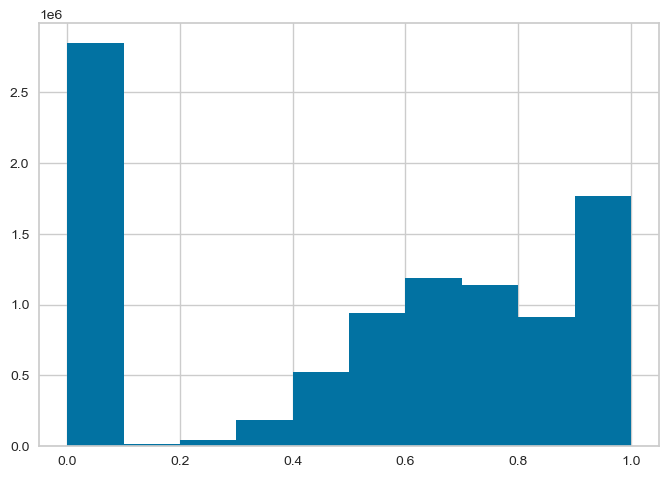

In [66]:
# load the data 
#(rioxarray library that opens raster/geospatial image files (like GeoTIFF, NetCDF, etc.) 
# and loads them as xarray DataArrays with geospatial metadata intact.)
# .squeeze() removes dimensions of size 1 from an array or DataArray.
data_raster = rxr.open_rasterio('Datasets/Sentinel-2_L2A_SWIR.tiff').squeeze()

data_raster.plot()
plt.title('')
plt.show()

In [67]:
data_raster

<xarray.DataArray (band: 3, y: 1274, x: 2500)> Size: 38MB
[9555000 values with dtype=float32]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 20kB 139.6 139.6 139.6 139.7 ... 144.2 144.2 144.2
  * y            (y) float64 10kB -28.56 -28.56 -28.56 ... -30.58 -30.58 -30.58
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:           Area
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    scale_factor:            1.0
    add_offset:              0.0

3 bands (Different SWIR wavelengths) \
1274 rows (height) \
2500 columns (width) \
x: Longitude coordinates \
y: Latitude coordinates \
SWIR (Short-Wave Infrared) data 

In [59]:
data_raster.values.shape

(3, 1274, 2500)

In [95]:
# Convert coordinates to decimal degrees (approximate)
crop_min_lat = -29.81  # Southernmost point (29° 48' 37" S)
crop_max_lat = -29.34  # Northernmost point (29° 20' 17" S)
crop_min_lon = 141.61  # Westernmost point (141° 36' 22" E)  
crop_max_lon = 142.15  # Easternmost point (142° 08' 47" E)

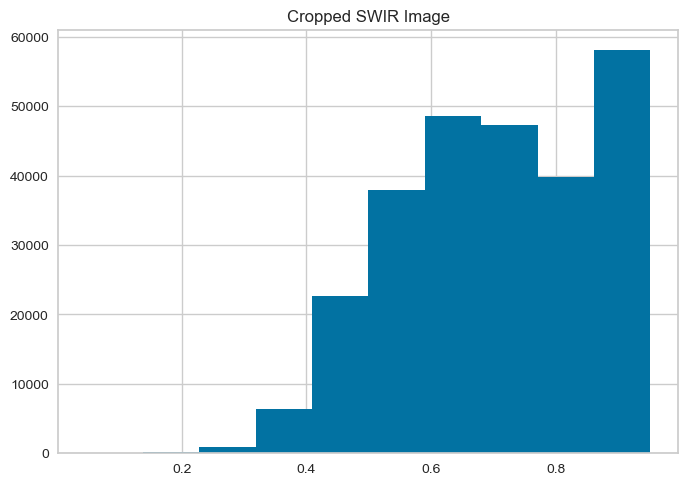

Original shape: (3, 1274, 2500)
Cropped shape: (3, 295, 296)


In [72]:
# Crop the raster using xarray selection
data_cropped = data_raster.sel(
    x=slice(crop_min_lon, crop_max_lon),
    y=slice(crop_max_lat, crop_min_lat)  # Note: y is reversed (max to min)
)

# Plot the cropped result
data_cropped.plot()
plt.title('Cropped SWIR Image')
plt.show()
print(f"Original shape: {data_raster.shape}")
print(f"Cropped shape: {data_cropped.shape}")

In [73]:
# Get new extent for the cropped image
min_x = float(data_cropped.coords['x'].min())
max_x = float(data_cropped.coords['x'].max())
min_y = float(data_cropped.coords['y'].min())
max_y = float(data_cropped.coords['y'].max())
extent_cropped = [min_x, max_x, min_y, max_y]

In [74]:
# min_x = float(data_raster.coords['x'].min())
# max_x = float(data_raster.coords['x'].max())
# min_y = float(data_raster.coords['y'].min())
# max_y = float(data_raster.coords['y'].max())

extent = extent_cropped
extent

[141.61061865234376,
 142.14991552734378,
 -29.808940491624895,
 -29.341492133854924]

In [83]:
# read the data returns a numpy array with just the pixel values
# data_array = np.array(data_raster)
data_array = data_cropped.values

print(f"Cropped data shape: {data_array.shape}")  # (3, 295, 296)

Cropped data shape: (3, 295, 296)


In [86]:
# reshape the input data from (band, row, col) to (row, col, band)
data_xyb = np.empty((data_cropped.shape[1], data_cropped.shape[2], data_cropped.shape[0]))
# loop through the bands to fill the empty array
for band in range(data_xyb.shape[2]):
    data_xyb[:, :, band] = data_array[band, :, :]

#reshape (1274, 2500, 3) to 2D array: (1274*2500, 3) = (3,185,000, 3)
data_reshaped = data_xyb.reshape(data_xyb.shape[0]*data_xyb.shape[1], -1)
# scale the data (each band value becoming 0 and 1)
data_reshaped = minmax_scale(data_reshaped, feature_range=(0, 1), axis=0, copy=False)
print(f"Final reshaped data shape: {data_reshaped.shape}")

Final reshaped data shape: (87320, 3)


In [87]:
# pca
# Creates PCA with all possible components (3 in this case)
pca = PCA()

# Transforms data to PC space
components = pca.fit_transform(data_reshaped)
# eigenvectors = pca.components_
# eigenvalues = pca.explained_variance_

#Explained Variance Ratio:
#How much of the dataset's total variability each component captures, expressed as a decimal between 0 and 1.
var_ratio = pca.explained_variance_ratio_

var_sum = 0
for i in range(len(var_ratio)):
    if var_sum >= 0.95:
        break
    else:
        var_sum += var_ratio[i]

selected_components = components[:, :i]
print('Number of components:', selected_components.shape[1])
print('var_ratio:',var_ratio)
selected_components

Number of components: 2
var_ratio: [0.8984667 0.0811271 0.0204062]


array([[-0.10438914,  0.11745548],
       [-0.00328162,  0.09145169],
       [ 0.10192656,  0.04562611],
       ...,
       [-0.00886486,  0.02238019],
       [-0.2281805 , -0.10543973],
       [-0.35823402, -0.14697717]])

# Elbow method

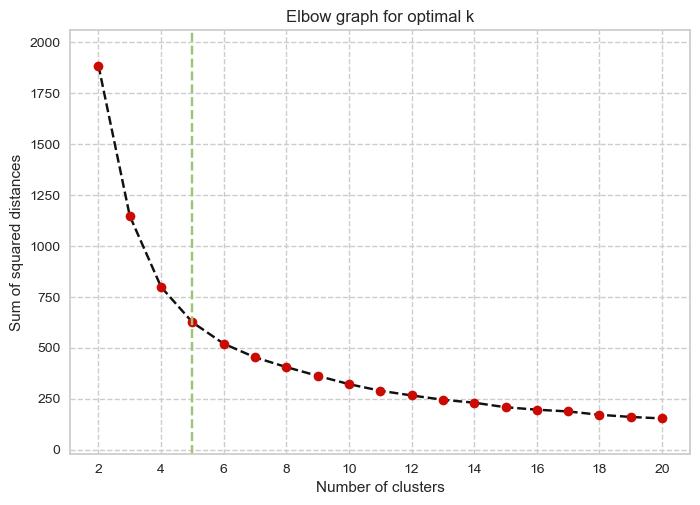

In [94]:
# elbow method
sum_squared_distance = []
range_n_clusters = range(2, 21)
for k in range_n_clusters:
    clusterer = cluster.KMeans(n_clusters=k, random_state=1)
    clusterer.fit(selected_components)
    sum_squared_distance.append(clusterer.inertia_)

range_ssd = max(sum_squared_distance) - min(sum_squared_distance)

plt.plot(range_n_clusters, sum_squared_distance, 'ko--', mfc='r')
plt.vlines(x=5, ymin=min(sum_squared_distance)-(0.1*range_ssd),
           ymax=max(sum_squared_distance)+(0.1*range_ssd), color='g', linestyles='dashed')
plt.xticks(range(2, 21, 2))
plt.ylim(min(sum_squared_distance)-(0.1*range_ssd), max(sum_squared_distance)+(0.1*range_ssd))
plt.xlabel('Number of clusters')
plt.ylabel('Sum of squared distances')
plt.title('Elbow graph for optimal k')
plt.grid(linestyle='--')
#plt.savefig('./Figures/pca_kmeans_sentinel2_elbow.png', dpi=300)
plt.show()

# visualizer = KElbowVisualizer(cluster.KMeans(random_state=1), k=(2, 21), timings=True)
# # fit the data
# visualizer.fit(selected_components)
# # finalize and render figure
# visualizer.show()

# k-means

Calinski-Harabasz score: 155050.6193
Davies-Bouldin score: 0.7555


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_11270/889984245.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow', n_clusters)


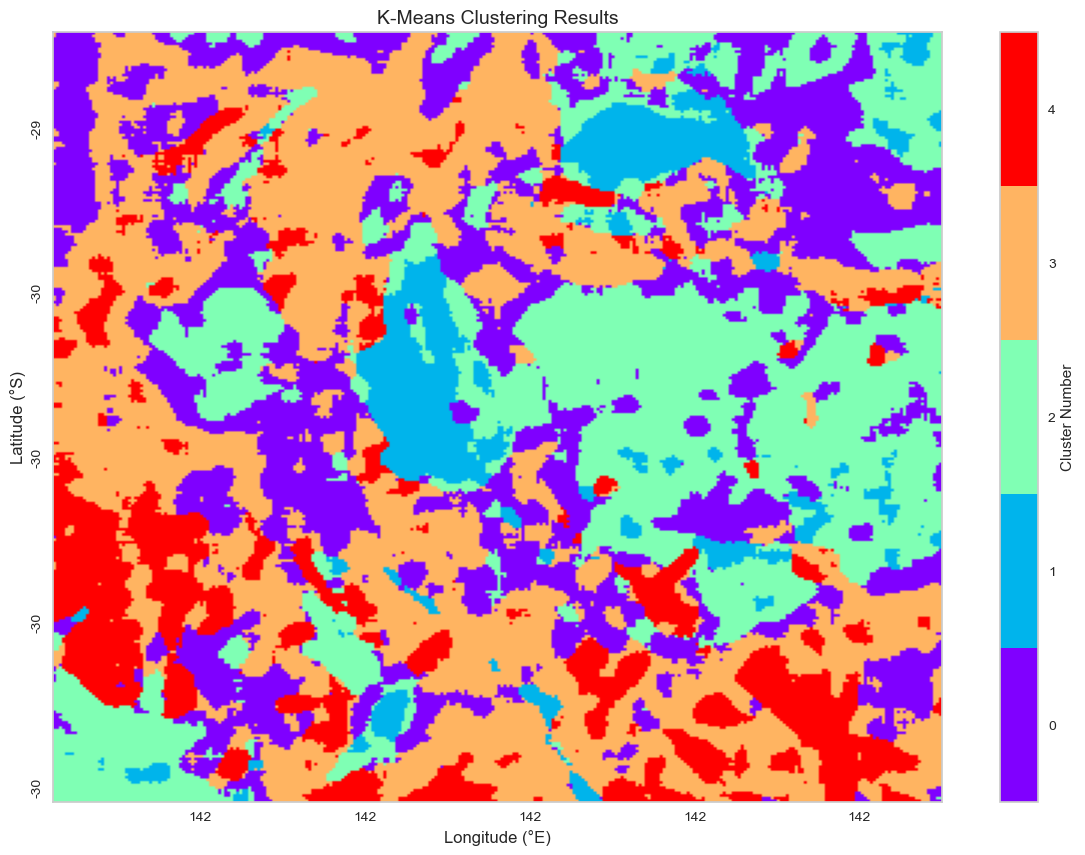

In [104]:
# k-means
n_clusters = 5

# create an object of the classifier
clusterer = cluster.KMeans(n_clusters=n_clusters, random_state=1)
# train
pred = clusterer.fit_predict(selected_components) # Train
# get cluster labels
labels = clusterer.labels_

# Calinski-Harabasz score
ch_score = calinski_harabasz_score(selected_components, labels)
# Davies-Bouldin score
# The minimum score is zero, and the lower values the better clustering performance
db_score = davies_bouldin_score(selected_components, labels)
print('Calinski-Harabasz score:', round(ch_score, 4))
print('Davies-Bouldin score:', round(db_score, 4))

# reshape the labels to a 3D array (single band)
labels = labels.reshape(data_array[0, :, :].shape)

def filter_function(invalues):
    invalues_mode = mode(invalues, axis=None, nan_policy='omit')
    return invalues_mode[0]

labels_major = generic_filter(labels, function=filter_function, size=7)

def plot_map(array, extent, n_clusters):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.f'))
    plt.yticks(rotation=90, va='center')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.f'))
    cmap = cm.get_cmap('rainbow', n_clusters)
    plt.imshow(array, cmap=cmap, extent=extent)
    cbar = plt.colorbar(label='Cluster Number')
    tick_locs = (np.arange(n_clusters) + 0.5)*(n_clusters-1)/n_clusters
    cbar.set_ticks(tick_locs)
    cbar.set_ticklabels(np.arange(n_clusters))
    plt.grid(False)
    # Add axis labels
    plt.xlabel('Longitude (°E)', fontsize=12)
    plt.ylabel('Latitude (°S)', fontsize=12)

    # Add a title
    plt.title('K-Means Clustering Results', fontsize=14)

plot_map(labels_major, extent, n_clusters)

# SOM

In [100]:
def plot_map(array, extent, n_clusters, title="Clustering Results"):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    plt.yticks(rotation=90, va='center')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    cmap = cm.get_cmap('rainbow', n_clusters)
    plt.imshow(array, cmap=cmap, extent=extent)
    cbar = plt.colorbar(label='Cluster Number')
    tick_locs = (np.arange(n_clusters) + 0.5)*(n_clusters-1)/n_clusters
    cbar.set_ticks(tick_locs)
    cbar.set_ticklabels(np.arange(n_clusters))
    plt.grid(False)
    plt.xlabel('Longitude (°E)', fontsize=12)
    plt.ylabel('Latitude (°S)', fontsize=12)
    plt.title(title, fontsize=14)  # Use the title parameter

 [ 1000 / 1000 ] 100% - 0:00:00 left 
 quantization error: 0.05135764841013708
Number of unique SOM clusters: 25


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_11270/1137972528.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow', n_clusters)


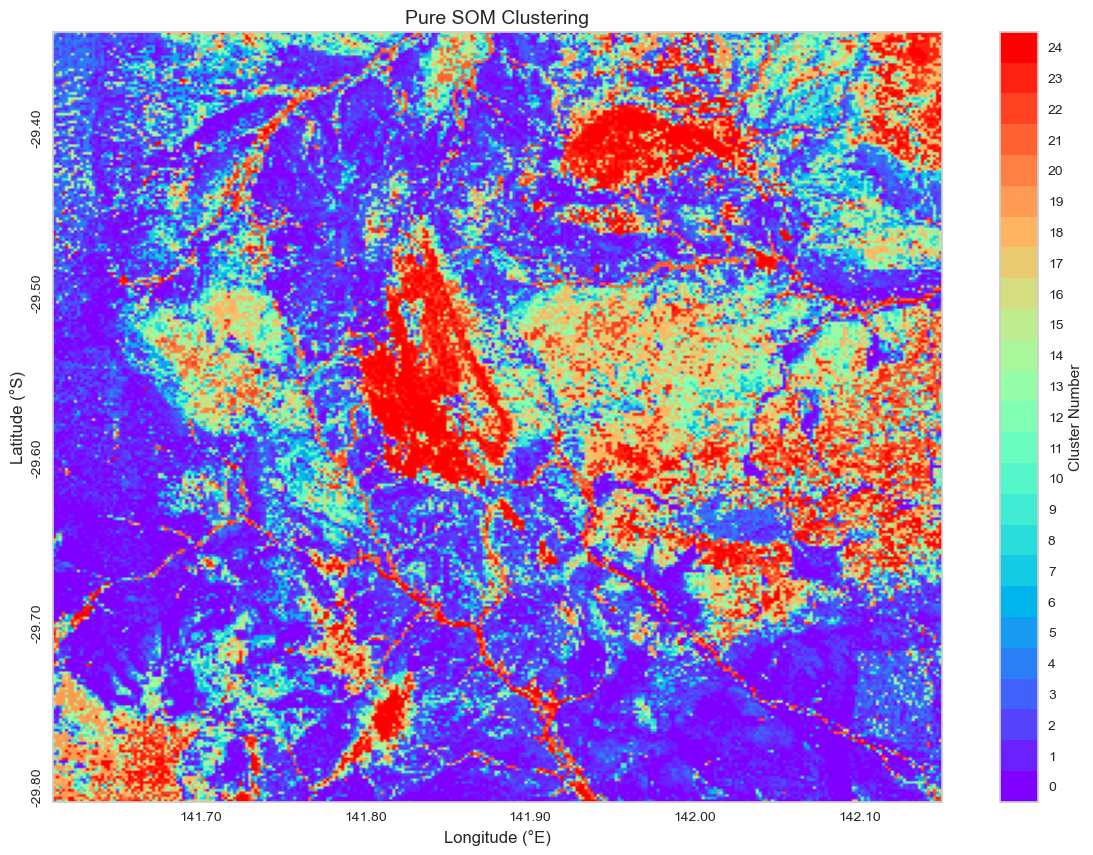

In [102]:
# Train your SOM (as before)
# SOM parameters
# Common configurations:
# For ~87k samples: 10×10 = 100 neurons (good balance)
# For fewer clusters: 5×5 = 25 neurons
# For more detail: 15×15 = 225 neurons
som_width = 5   # Width of SOM grid
som_height = 5  # Height of SOM grid
input_len = data_reshaped.shape[1]  # 3 SWIR bands
sigma = 1.0      # Neighborhood radius
learning_rate = 0.5


som = MiniSom(som_width, som_height, input_len, 
              sigma=sigma, learning_rate=learning_rate,
              neighborhood_function='gaussian', random_seed=42)
som.random_weights_init(data_reshaped)
som.train_batch(                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            , num_iteration=1000, verbose=True)

# Get cluster labels directly from SOM winning neurons
def get_som_clusters(som, data):
    """Each winning neuron becomes a cluster ID"""
    clusters = []
    for sample in data:
        winner = som.winner(sample)  # Get (x, y) coordinates of winning neuron
        cluster_id = winner[0] * som.get_weights().shape[1] + winner[1]  # Convert to single ID
        clusters.append(cluster_id)
    return np.array(clusters)

# Get cluster labels
som_labels = get_som_clusters(som, data_reshaped)
print(f"Number of unique SOM clusters: {len(np.unique(som_labels))}")

# Reshape back to image format
labels_image = som_labels.reshape(data_xyb.shape[0], data_xyb.shape[1])

# Plot results
n_clusters = len(np.unique(som_labels))
plot_map(labels_image, extent, n_clusters, "Pure SOM Clustering")
plt.show()